# 현실의 데이터 15: 통신사 고객 이탈 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/15_telco_churn.ipynb)

**분야**: 플랫폼 · 서비스 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 고객 이탈 (churn) · 구독 서비스 · 리텐션 마케팅

> 통신사 가입자 7천 명. 다음 달 떠날 사람을 미리 알 수 있을까?

**데이터**: IBM Telco Customer Churn (약 1MB). IBM 샘플 데이터: 가상의 통신사 가입자 7,043명. 가입 기간 · 요금제 · 부가 서비스 · 결제 방법 · 월 요금 · 지난달 해지 여부.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 가입자 한 명 |
| ② 입력 X | 가입 기간 · 계약 종류 · 인터넷 · 부가 서비스 · 결제 방법 · 월 요금 |
| ③ 출력 y | 해지했나 (Churn) |
| ④ 평가지표 | 재현율 · 정밀도 (붙잡을 사람 고르기) |
| ⑤ 기준선 | 아무도 안 떠난다 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [IBM 샘플 데이터 저장소 (Telco Customer Churn)](https://github.com/IBM/telco-customer-churn-on-icp4d)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(download(URL, "data/telco_churn.csv"))
print(df.shape)
df.sample(5, random_state=0)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2200,6296-DDOOR,Female,0,No,No,19,Yes,No,DSL,No,...,No,No,Yes,No,One year,No,Electronic check,58.20,1045.25,No
4627,3680-CTHUH,Male,0,No,No,60,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Credit card (automatic),116.60,7049.5,No
3225,4931-TRZWN,Female,0,No,No,13,Yes,No,DSL,Yes,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,71.95,923.85,No
2828,8559-WNQZS,Male,0,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.45,20.45,No
3768,3537-HPKQT,Female,0,Yes,No,55,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Credit card (automatic),77.75,4266.4,No


## 열어 보기

`TotalCharges` 는 숫자인데 글자로 읽혔다. 왜일까? (공백으로 적힌 빈칸, 1주 3차시) 그리고 계약 종류마다 해지율은?

str | blank TotalCharges: 11
churn rate 26.5%
{'Month-to-month': 0.427, 'One year': 0.113, 'Two year': 0.028}


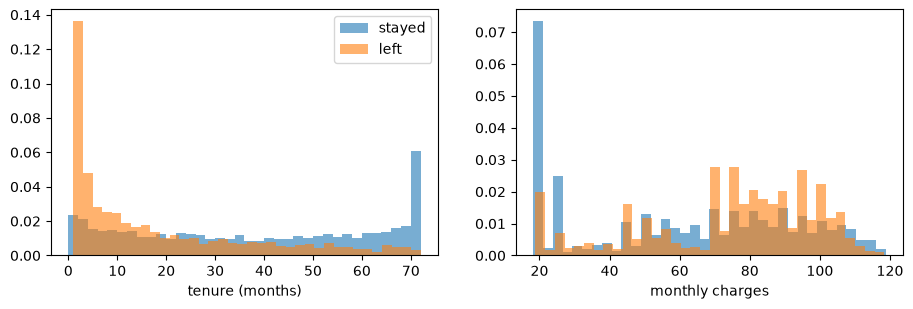

In [3]:
print(df.dtypes["TotalCharges"], "| blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["y"] = (df["Churn"] == "Yes").astype(int)
print(f"churn rate {df['y'].mean():.1%}")
print(df.groupby("Contract")["y"].mean().round(3).to_dict())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for lab, name in [(0, "stayed"), (1, "left")]:
    axs[0].hist(df.loc[df.y == lab, "tenure"], bins=36, alpha=0.6, density=True, label=name)
    axs[1].hist(df.loc[df.y == lab, "MonthlyCharges"], bins=36, alpha=0.6, density=True, label=name)
axs[0].set_xlabel("tenure (months)"); axs[1].set_xlabel("monthly charges"); axs[0].legend(); plt.show()

## 문제 하나 골라 보기: 가입자 → 떠날까

기준선 = 아무도 안 떠난다. 모델 = 그레이디언트 부스팅. 마케팅 팀이 **할인 쿠폰을 보낼 상위 500명** 을 고른다면, 그중 진짜 떠날 사람은 몇 명일까?

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "y"]), dtype=float)
Xtr, Xte, ytr, yte = train_test_split(X, df["y"].values, test_size=0.3, stratify=df["y"], random_state=0)
m = HistGradientBoostingClassifier(random_state=0, max_iter=200, learning_rate=0.05).fit(Xtr, ytr)
score = m.predict_proba(Xte)[:, 1]
print(f"nobody leaves: accuracy {np.mean(yte == 0):.1%}")
print(f"model: accuracy {np.mean((score > 0.5) == yte):.1%}, ROC-AUC {roc_auc_score(yte, score):.2f}")
top = np.argsort(-score)[:500]
print(f"top 500 by score: {yte[top].sum()} will leave ({yte[top].mean():.0%})  vs  random 500: about {500 * yte.mean():.0f}")

nobody leaves: accuracy 73.5%
model: accuracy 78.8%, ROC-AUC 0.83
top 500 by score: 303 will leave (61%)  vs  random 500: about 133


**관찰**: 월 단위 계약 · 짧은 가입 기간 · 높은 요금이 이탈과 함께 간다. 실제로는 '떠날 사람' 보다 **'쿠폰을 주면 남을 사람'** 을 찾아야 돈이 된다 (어차피 떠날 사람, 어차피 남을 사람에게 주는 쿠폰은 낭비).

## 다른 문제로 바꿔 보기

- **언제 떠날까**: '떠났나' 대신 '몇 달 뒤 떠날까' 를 맞히면 생존 분석이 된다 (tenure 를 쓴다).
- 쿠폰 효과를 알려면 어떤 데이터가 더 필요할까? (쿠폰을 무작위로 준 실험)

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |